# Glidande gjennomsnitt og finare tidsakse

Målingane varierer mykje frå minutt til minutt. For å sjå dei store trendane kan me rekne ut eit **glidande gjennomsnitt**: for kvart tidspunkt reknar me snittet av alle målingane i eit «vindauge» bakover i tid, til dømes dei siste 24 timane.

Her brukar me tidspunktet som **indeks** (radnamn) i tabellen. Då kan Pandas bruke tida direkte når det reknar og plottar.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams["figure.figsize"] = (10, 4)

# index_col="dato" gjer tidspunktet til indeks
data = pd.read_csv("utestasjon-bones.csv", parse_dates=["dato"], index_col="dato")
data.head()

,temperatur,lufttrykk,luftfuktighet,pm25,pm10
dato,,,,,
2022-11-15 18:59:55.540108,25.967480,1000.728005,25.025103,1,1
2022-11-15 19:00:28.377546,25.853753,1000.696595,25.183850,1,3
2022-11-15 19:01:01.211174,26.063974,1000.721758,25.257006,2,2
2022-11-15 19:01:33.977001,26.058929,1000.690602,25.218070,0,2
2022-11-15 19:02:06.806198,25.597409,1000.692818,25.406987,0,0


In [2]:
# Med tid som indeks kan me velje ut periodar slik:
data.loc["2022-11-20"]  # Heile 20. november

,temperatur,lufttrykk,luftfuktighet,pm25,pm10
dato,,,,,
2022-11-20 00:00:09.982375,-0.728444,1011.878058,41.437077,28,33
2022-11-20 00:00:42.914213,-0.924463,1011.889402,41.260228,28,36
2022-11-20 00:01:16.201385,-0.860741,1011.882581,41.073116,25,25
2022-11-20 00:01:48.850526,-0.818565,1011.870084,40.927480,28,34
2022-11-20 00:02:21.504052,-0.805270,1011.872612,40.797197,31,37
...,...,...,...,...,...
2022-11-20 23:57:28.284655,-0.714959,1004.757721,38.360723,10,15
2022-11-20 23:58:01.001809,-0.754384,1004.747741,38.360511,13,16
2022-11-20 23:58:34.069879,-0.829109,1004.726060,38.380989,15,21


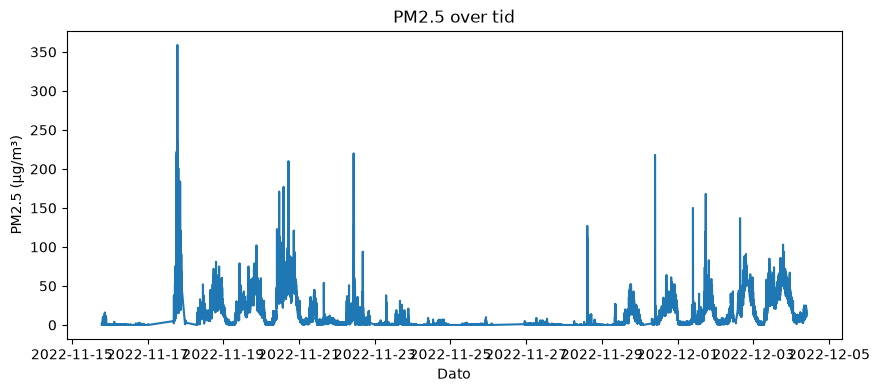

In [3]:
plt.plot(data.index, data["pm25"])
plt.title("PM2.5 over tid")
plt.xlabel("Dato")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

## Glidande gjennomsnitt

`rolling("1D")` lagar eit vindauge på éin dag. Prøv å endre til `"6h"`, `"3D"` eller `"7D"` og sjå kva som skjer med kurva. Eit større vindauge gir ei glattare kurve, men små endringar forsvinn.

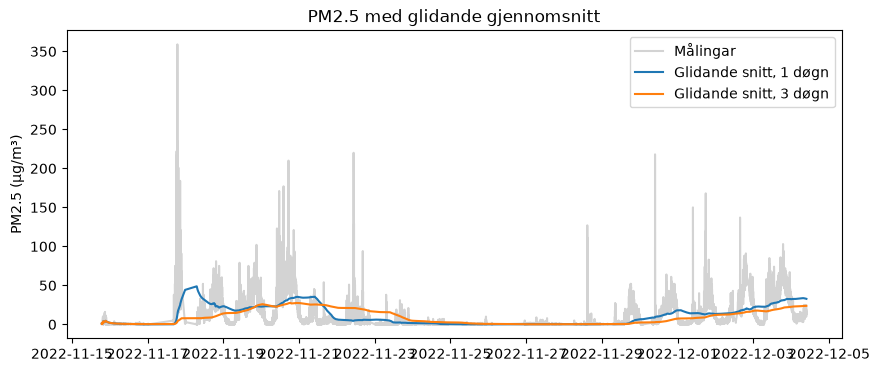

In [4]:
data["pm25_1d"] = data["pm25"].rolling("1D").mean()
data["pm25_3d"] = data["pm25"].rolling("3D").mean()

plt.plot(data.index, data["pm25"], color="lightgray", label="Målingar")
plt.plot(data.index, data["pm25_1d"], label="Glidande snitt, 1 døgn")
plt.plot(data.index, data["pm25_3d"], label="Glidande snitt, 3 døgn")
plt.title("PM2.5 med glidande gjennomsnitt")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

## Formatere tidsaksen

Med `matplotlib.dates` kan me velje kor ofte det skal vere ein merkelapp på x-aksen, og korleis datoen skal skrivast. Dataa dekkjer knapt tre veker, så éin merkelapp annakvar dag passar bra.

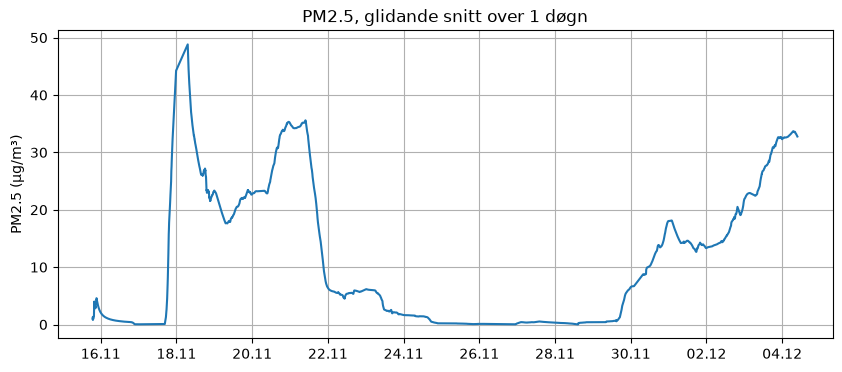

In [5]:
fig, ax = plt.subplots()
ax.plot(data.index, data["pm25_1d"])
ax.set_title("PM2.5, glidande snitt over 1 døgn")
ax.set_ylabel("PM2.5 (µg/m³)")

ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))    # Merkelapp annakvar dag
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))  # Skriv som dag.månad
ax.grid()
plt.show()

## To y-aksar i same figur

Temperatur og svevestøv har ulike einingar og ulik storleik. Med `ax1.twinx()` får me ein y-akse på kvar side. Er det nokon samanheng mellom temperatur og svevestøv?

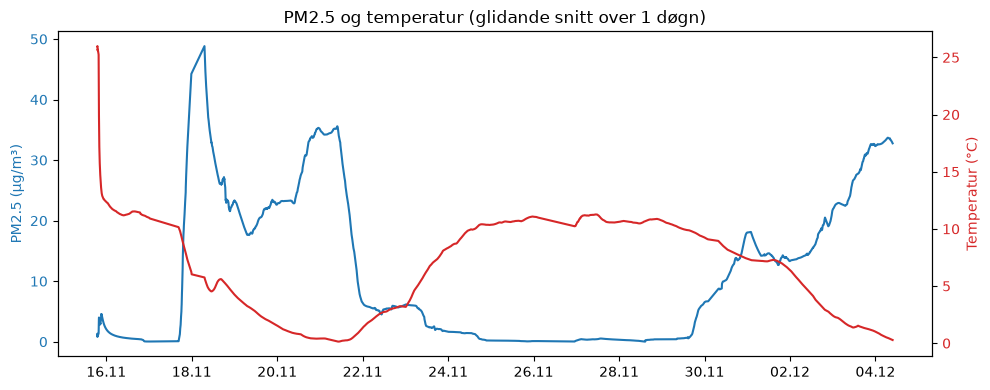

In [6]:
data["temp_1d"] = data["temperatur"].rolling("1D").mean()

fig, ax1 = plt.subplots()

ax1.plot(data.index, data["pm25_1d"], color="tab:blue")
ax1.set_ylabel("PM2.5 (µg/m³)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()  # Ny y-akse som deler x-aksen med ax1
ax2.plot(data.index, data["temp_1d"], color="tab:red")
ax2.set_ylabel("Temperatur (°C)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

ax1.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax1.set_title("PM2.5 og temperatur (glidande snitt over 1 døgn)")
fig.tight_layout()
plt.show()